# Przetwarzanie i Rozpoznawanie obrazów na przykładzie znaków drogowych

## 1. Akwizycja i Analiza danych wraz ze schmetem blokowym przetwarzania
Dane treningowe i testowe (zdjęcia) zebrałem za pomocą apartu cyfrowego.  
Surowe dane czyli pliki bezpośrednio stworzone przez aparat podzieliłem na główne klasy znaków `zakazu`, `nakazu`, `informacyjne`, `ostrzegawcze`, `uzupełniające` dodatkowo zostawiłem zdjęcia zawierające więcej niz jeden znak.

### 1. Galerie
Galeria zdjęć: [google drive](https://drive.google.com/drive/folders/1ERfEODLCpq13N1ZiApyREA9czmsD-ryz?usp=sharing)  
Galiera obiektów testowych: [obiekty testowe](https://drive.google.com/drive/folders/1dYQ4TixCfVej8i2K6ym_8eDxlWGlbofp?usp=sharing)

Z duzych zdjęć ręcznie wyciąłem same znaki drogowe uzyskując, nieprzetworzone obiekty testowe.
Znormalizowałem znaki do wielkości 128x128px za pomocą skryptu

### 2. Struktura projektu
Wszystkie zdjęcia po każdym etapie sa zachowywane w swoich katalogach. Pliki notatnika i pomocnicze znajduja się w top level directory.
```
└── data
    ├── assets
    │   └── sign_models
    ├── processed
    │   └── normalized
    │       ├── informacyjne
    │       ├── nakazu
    │       ├── ostrzegawcze
    │       ├── uzupelniajace
    │       └── zakazu
    └── raw
        ├── cropped
        │   ├── informacyjne
        │   ├── nakazu
        │   ├── ostrzegawcze
        │   ├── uzupelniajace
        │   └── zakazu
        └── originals
            ├── informacyjne
            ├── nakazu
            ├── ostrzegawacze
            ├── uzupelniajace
            ├── wiele_znakow
            └── zakazu
```



In [52]:
# instalacja pakietow
%pip install opencv-python numpy matplotlib
# Importy
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb

from pathlib import Path

Note: you may need to restart the kernel to use updated packages.


In [22]:
# Normalizacja znakow do wielkości 128 x 128 px i zapis do osobnego folderu

SRC = Path("./data/raw/cropped")
NORMALIZED_DST = Path("./data/processed/normalized")
SIZE = 128

n_ok = n_fail = 0
for f in sorted(SRC.rglob("*")):
    if f.suffix.lower() not in { ".JPG", ".jpg" }:
        continue
    img = cv2.imread(str(f))
    if img is None:
        print("failed to read:", f)
        n_fail += 1
        continue
    h, w = img.shape[:2]
    interp = cv2.INTER_AREA if max(h, w) > SIZE else cv2.INTER_CUBIC
    out = NORMALIZED_DST / f.relative_to(SRC)
    out.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(out), cv2.resize(img, (SIZE, SIZE), interpolation=interp))
    n_ok += 1

print(f"processsd: {n_ok}, failed: {n_fail} -> {NORMALIZED_DST.resolve()}")


processsd: 127, failed: 0 -> /Users/marcinbondaruk/studia/technika_obrazowa/projekt_1/data/processed/normalized


Planuję powiększyć zbiór danych dlatego potrzebuję funkcji pomocniczej która pominie klasy znaków których mam za mało.

In [23]:
FOLDER = Path("./data/processed/normalized")   # podfoldery = klasy
SKIP_CLASSES = {"uzupelniajace"}          # za mało zdjęć

data = {}   # klasa -> lista obrazów (BGR)
for class_dir in sorted(p for p in FOLDER.iterdir() if p.is_dir() and p.name not in SKIP_CLASSES):
    files = [f for f in sorted(class_dir.iterdir()) if f.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    data[class_dir.name] = [cv2.imread(str(f)) for f in files]

{name: len(images) for name, images in data.items()}

{'informacyjne': 30, 'nakazu': 17, 'ostrzegawcze': 27, 'zakazu': 51}

### Analiza danych
Analizujemy znaki drogowe. Znaki drogowe mają przynajmniej 3 cechy charakterystyczne z czego ja skupiam się w tej chwili na pierwszych dwóch:
1. Kształt
2. Kolory
3. Są dobrze widoczne w nocy po skierowaniu na nie światła (muszę uzupełnić zbiór o nocne zdjęcia)


In [24]:
# funckje pomocnicze

def remove_noise(img):
    # filtr Gaussa 5x5 wygładza szum.
    return cv2.GaussianBlur(img, (5, 5), 0)

# funkcja remove background przygotowuje maskę
def remove_background(img):
    # Otsu na kanale S -> maska znaku (255 = znak, 0 = tło)
    saturation = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[..., 1]
    _, mask = cv2.threshold(saturation, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    # usuwa plamki
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    # zaślepia dziury
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return mask
    largest = max(contours, key=cv2.contourArea)    # zakładam że największy obiekt = znak choć podejrzewam że to jest do poprawy
    result = np.zeros_like(mask)
    cv2.drawContours(result, [cv2.convexHull(largest)], -1, 255, -1)   # -1 = wypełnij środek
    return result

#### Analiza kolorów

Na początek postanowiłem skupić się na najbardziej charakterystycznych kolorach dla znaków i zbadać mój dataset w przestrzeni HSV oraz określić zawartość koloru w określonej klasie znaków.  
W celu analizy koloru i pozostałych cech stostuję następującą kolejność przetwarzania:
- Odszumianie Gauss
- Progowanie OTSU
- przekształcenia morfologiczne do załatania dziur
- znalezienie konturów -> zwrócenie maski
- od oryginalnego obrazu odejmuję maskę, tło uzupelniajac kolorem szarym i nastepnie badam obraz w przesteni HSV

In [58]:
# kolory wystepujace na znakach (z wylaczeniem znakow pomocniczych typu zjazdy)
COLOR_NAMES = ["biały", "niebieski", "czerwony", "żółty", "czarny", "inne"]
PALETTE = np.array([[255, 255, 255], [200, 80, 0], [0, 0, 220],
                    [0, 220, 255], [0, 0, 0], [255, 0, 255]], np.uint8)   # BGR, ta sama kolejność
PLOT_COLORS = ["white", "blue", "red", "yellow", "black", "magenta"]


def color_labels(img):
    # każdy piksel dostaje numer koloru: 0 biały, 1 niebieski, 2 czerwony, 3 żółty, 4 czarny, 5 inne
    h, s, v = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2HSV))
    bright_colored = (v >= 60) & (s >= 60)
    conditions = [
        (v >= 60) & (s < 60),                       # biały: jasny, bez koloru
        bright_colored & (h >= 95) & (h < 135),     # niebieski
        bright_colored & ((h < 18) | (h >= 165)),   # czerwony (leży na obu końcach skali H)
        bright_colored & (h >= 18) & (h < 38),      # żółty
        v < 60,                                     # czarny: ciemny
    ]
    return np.select(conditions, [0, 1, 2, 3, 4], default=5)


Wizualizacja kolejnych etapy obróbki:

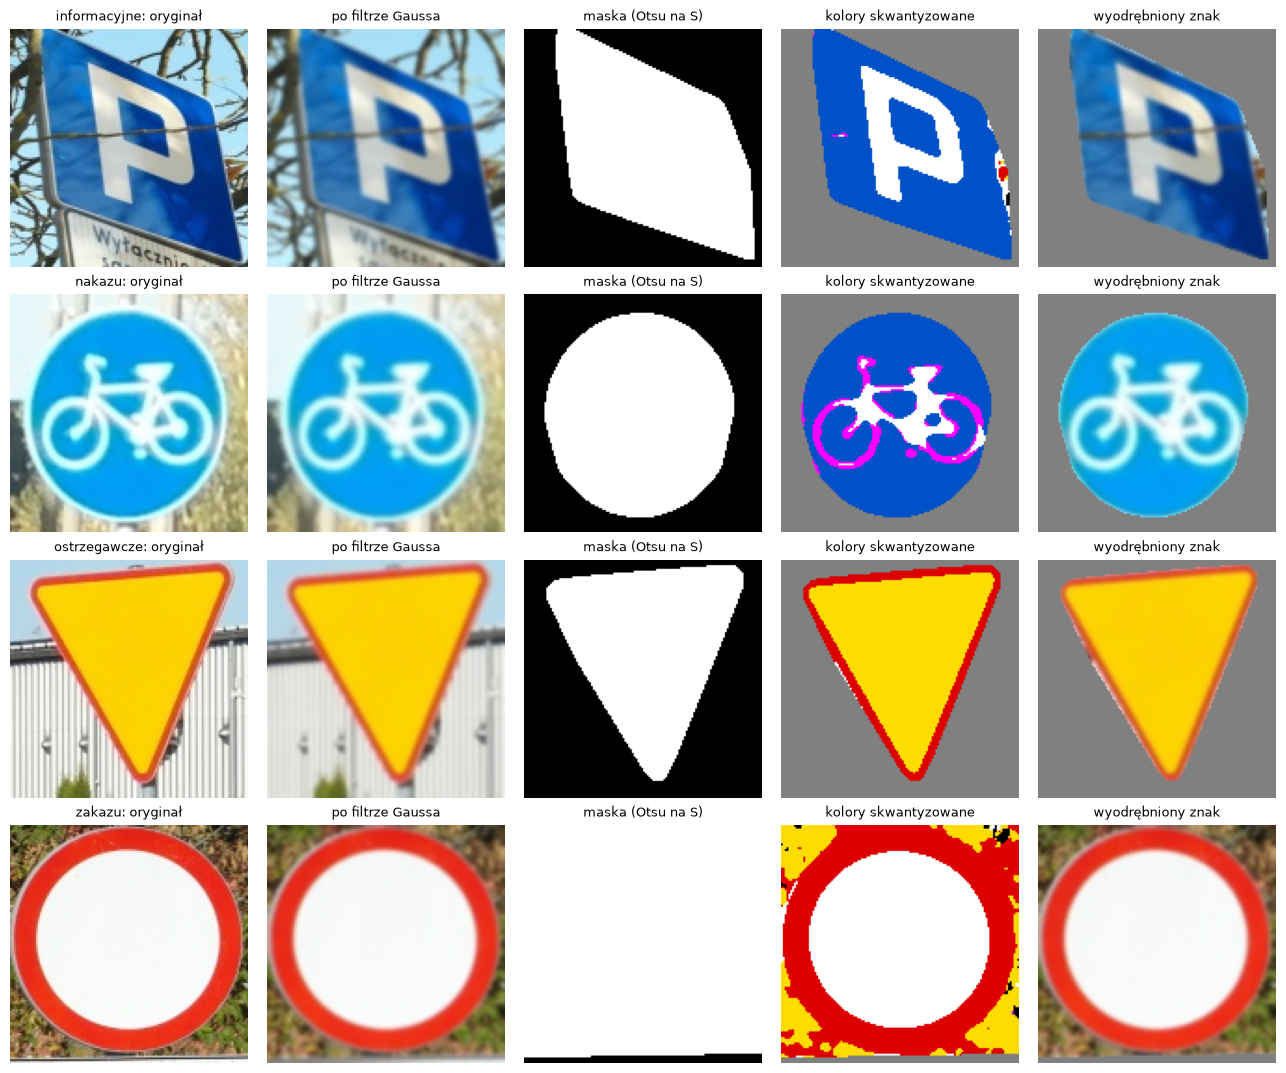

In [55]:
items = list(data.items())
fig, axes = plt.subplots(len(items), 5, figsize=(13, 2.7 * len(items)), squeeze=False)
for row, (cls, images) in zip(axes, items):
    img = images[np.random.randint(len(images))]
    clean = remove_noise(img)
    mask = remove_background(clean)

    quantized = PALETTE[color_labels(clean)]
    quantized[mask == 0] = 128                      # tło na szaro
    sign = np.full_like(img, 128)
    sign[mask > 0] = clean[mask > 0]

    columns = [img, clean, mask, quantized, sign]
    titles = [f"{cls}: oryginał", "po filtrze Gaussa", "maska (Otsu na S)", "kolory skwantyzowane", "wyodrębniony znak"]
    for ax, column, title in zip(row, columns, titles):
        ax.imshow(column if column.ndim == 2 else cv2.cvtColor(column, cv2.COLOR_BGR2RGB), cmap="gray")
        ax.set_title(title, fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

In [59]:
pixels = {}
for cls, images in data.items():
    h_all, s_all, v_all, labels_all = [], [], [], []
    for img in images:
        img = remove_noise(img)
        mask = remove_background(img) > 0
        h, s, v = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2HSV))
        h_all.append(h[mask])
        s_all.append(s[mask])
        v_all.append(v[mask])
        labels_all.append(color_labels(img)[mask])
    pixels[cls] = {"h": np.concatenate(h_all), "s": np.concatenate(s_all),
                   "v": np.concatenate(v_all), "labels": np.concatenate(labels_all)}

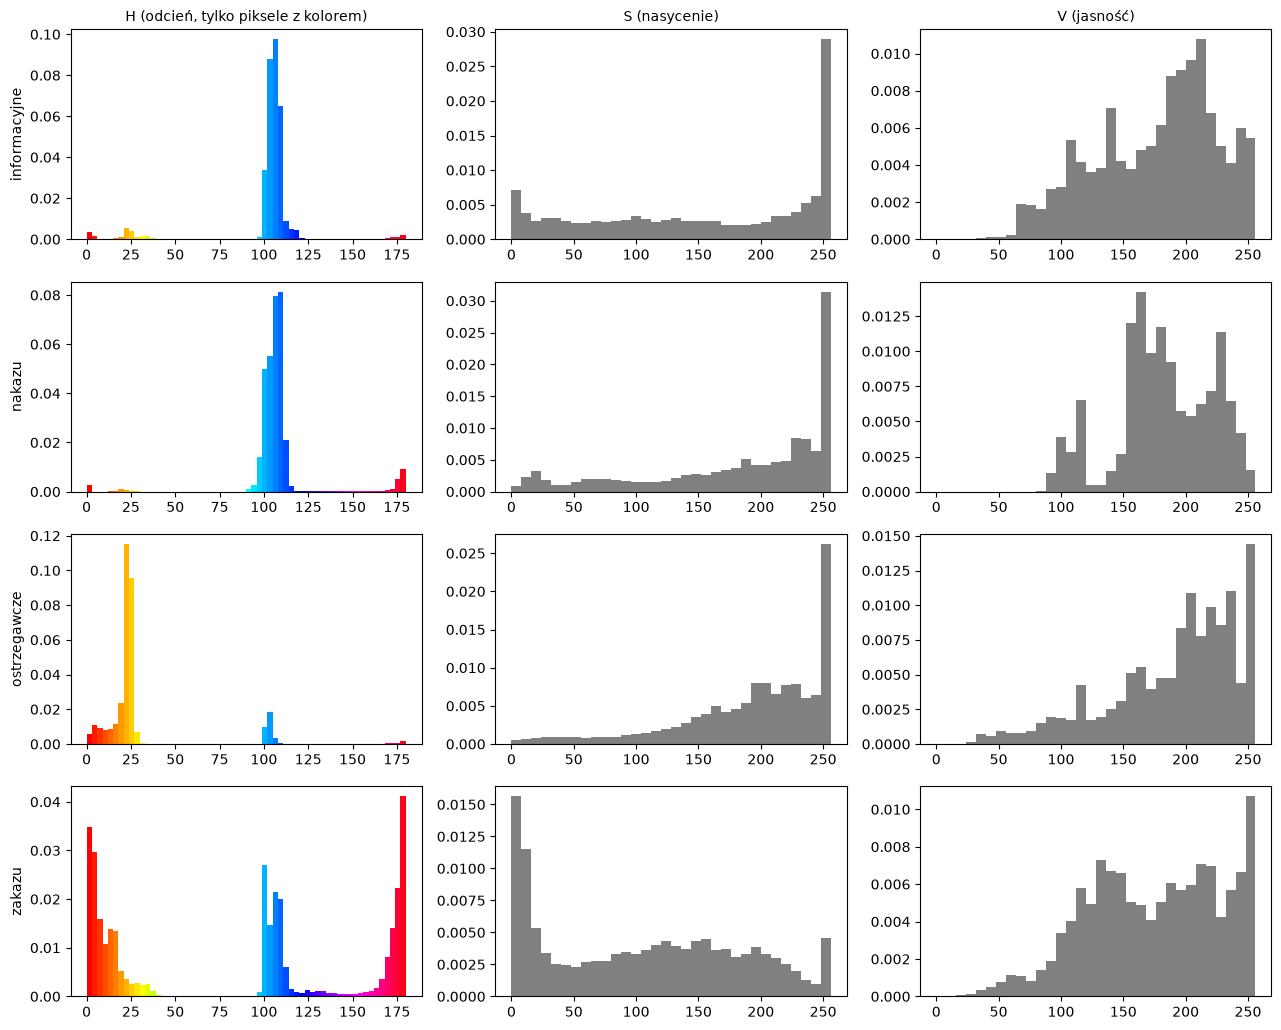

In [60]:
fig, axes = plt.subplots(len(pixels), 3, figsize=(13, 2.6 * len(pixels)), squeeze=False)
for row, (cls, p) in zip(axes, pixels.items()):
    colored = (p["s"] >= 60) & (p["v"] >= 60)       # odcień ma sens tylko dla pikseli z kolorem
    _, bins, bars = row[0].hist(p["h"][colored], bins=60, range=(0, 180), density=True)
    for left_edge, bar in zip(bins, bars):
        bar.set_facecolor(hsv_to_rgb([left_edge / 180, 1, 1]))   # słupek w kolorze swojego odcienia
    row[1].hist(p["s"], bins=32, range=(0, 256), density=True, color="gray")
    row[2].hist(p["v"], bins=32, range=(0, 256), density=True, color="gray")
    row[0].set_ylabel(cls)
for ax, title in zip(axes[0], ["H (odcień, tylko piksele z kolorem)", "S (nasycenie)", "V (jasność)"]):
    ax.set_title(title, fontsize=10)
plt.tight_layout()
plt.show()

Z analizy histogramów HSV stwierdzam że:
1. Odcień w HSV będzie najlepszą cechą częściowo umożliwiającą rozpoznanie znaku. W znakach informacyjnych oraz nakazu tego się spodziewałem jednak w znakach zakazu mogę stwierdzić że próbka zakazu potoju/zatrzymywania się jest za duża.
2. Nasycenie moze pomoc w identyfikacji znaków zakazu bo duża część z nich zawiera białe tło na co wskazuje słupek przy 0
3. Jasność w niczym mi nie pomoże, mówi nam tyle ze zbiór moich próbek jest dobrze doświetlony - składa się z samych dziennych zdjęć

Dla barw istotny będzie % skład danej klasy znaków:

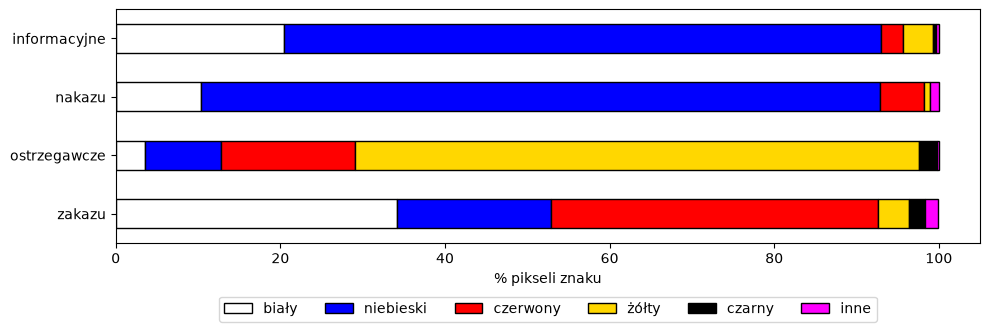

,biały,niebieski,czerwony,żółty,czarny,inne
informacyjne,20.5,72.5,2.6,3.7,0.3,0.4
nakazu,10.3,82.6,5.3,0.7,0.0,1.1
ostrzegawcze,3.5,9.3,16.3,68.5,2.2,0.2
zakazu,34.2,18.7,39.7,3.8,1.9,1.6


In [57]:
shares = pd.DataFrame(
    {cls: np.bincount(p["labels"], minlength=6) / len(p["labels"]) * 100 for cls, p in pixels.items()},
    index=COLOR_NAMES,
).T.round(1)

shares.plot.barh(stacked=True, color=PLOT_COLORS, edgecolor="black", figsize=(10, 3.5))
plt.xlabel("% pikseli znaku")
plt.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
shares

### Analiza Kształtu
Do analizy kształtu wykorzystałem wzory z lekcji 5.

Badam zwartość oraz prostokątność

In [68]:
rows = []
for cls, images in data.items():
    for img in images:
        mask = remove_background(remove_noise(img))
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            continue
        contour = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(contour)
        perimeter = cv2.arcLength(contour, True)
        _, (a, b), _ = cv2.minAreaRect(contour)
        if area == 0 or a * b == 0:
            continue
        rows.append({"klasa": cls,
                     "R_z (zwartość)": perimeter ** 2 / (4 * np.pi * area),
                     "R_p (prostokątność)": area / (a * b)})
features = pd.DataFrame(rows)
features.groupby("klasa").agg(["mean", "std"]).round(2)

R_z (zwartość)       R_p (prostokątność)      
                       mean   std                mean   std
klasa                                                      
informacyjne           1.36  0.23                0.88  0.12
nakazu                 1.23  0.16                0.80  0.03
ostrzegawcze           1.53  0.15                0.64  0.12
zakazu                 1.26  0.19                0.82  0.09

Na podsawie powyższych wyników stwierdzam że znaki zakazu i nakazu są najbardziej zwarte (okrągłe) po odjęciu odchyleniam duże odchylenie może być spowodowane tym że nie "odkształcałem znaków" zatem kołowe znaki na zdjęciach mog być eliptyczne.  
znaki informacyjne wypadają dość kwadratowo - tego się spoedziałem natomiast zakazu stanowią około połowę swojej kwadratowej powierzchni czyniąc je najbardziej trójkątnymi.

Wnioskuję że będę mógł z sukcesem użyć cech kształtu wraz z kolorem do określenia jednozczanie klasy znaków.

### Schemat przetwarzania

Schemat blokowy jest utworzony z pomocą języka opisu diagramów [Mermeid](https://mermaid.live/)  
Jeśli link do wyrenderowanej wersji wygasł uzupełnię notatnik o PNG  
[Diagram](https://mermaid.live/view#pako:eNp9Vt1O20gUfpUjVyuBZCghMVCri5QG01ZbQRXYrtTNCo3tSTKxPWPN2Gvsihuk7t7vDar6GNz2DvIi-yR7xn-J-dkgEXvm_H3f-c5Mvhie8KlhGxM-DUXmzYlM4PxowgE_jMdpsvH7xHjtHp66khSQ0cXyu8dElr9-6R6-duXLw8Jf3H_zGAWPLK_pApRHeQ4bb96ONyfGH5sTXsVSqTuTJJ7Dx7GDET_KgiYZkQXh6Jqp5P5bzCk6VNb641MumKJV-jH108BbEFBFGqVt8ikLEwlvSaoUAevuxjIhy2fLa-IXlSlEJJG5l3cie4InkqikCv1bLu9uM14WEtQ7qwy4klGpMDMign__-gfenX0yIRYJjWD0YfjOKc04gYBwElL4BBuhCEjIEdZa5AVRXGjuNp8CCVtbh21Z1S7l_iPuzpy3WPMZnUWUJwTp6MQSiUorSB-lmImszDsLhVsWc4q7K1RY6_IazmwoOAnAJdIvGDaPE5VjGTlwtvwByfJadDJEQsZzEYpZXuUZFbkqvILqRBFRAYMNNJlqC0Y222wiphz6dzd9SFWaEYhDEgXMBC8UCF23DQqkLmYEsIxUPugW4T7zSUJV0y_37lZquv0cl5HhNpEKdOtFRkHFd7cLTk2oFBKLkACDWIpYSG_BQLgZoz5nnUxSsAsPTZo8HquUPT5936ZwRYrl8Bm44rKtgZglV5gGZaeJuP-qoXL0T-ijFJIqVtS6PhEyIiErdDNxs4gYkWknoUIt1b30BfR2D-5u8B_El7Dx_uTcGV8Mx84QwtSF0a9v3o82H0mi1Naqc5XUWk7L1wZ4-1KV-LwQj53hOQJwAoWKLefSo978wZCFQl5MKUlS2bRuhEY5DhnurGkRwSV5xQDOlkZpVTa6tdoiRVVouf4EMQsUDRkSv_zh05moY3USqzmJ6dOJVZFgnLXpLmrZ6ilIIWRekUe5XW3h6ZTgxN7_DeOLwtTaUYnAzia8WY07eeuMF39SLxGy1hAN8LkkB-WnEqSdyAprW0Msltf3X-sp0pYmFFvKE5LCxvK71ColsGOC8BFDWFr1Nv-H6rKJ3WKeI-dZ06d6PvpwhqB-CfGImLLg0ekTcF5hbi008mDr5GTVafgZ-lsWnjILN8QDRhU58qLuvypG_KbZnaCoLsZx2i4UrU_rzy7T0596BXK2uoWykui8Yhq7yfPqO8Cwz0Ys4WPdjzD71GOKCV7ffUfUy4sFsSFAaKQSS5sZX0iRYs_qb1QJ3m0zkmFHy7FkfKqH3MsX5QXX3ojl7VqWUF8C1XJzC5Q7en6r5dVU1nfFesufNOm2ujLp9rqLHx_qairwTZ0eglZHdIoTQGN9nob2C8dxjo4dE6GKgNovrP5g-GbfLIuyX-zu7fas0QNnSb3Gt3dsOSvfneM9x9prfHcG_cHuQ19OU6QkrP2Pe86xc7DKjdGsYZt7hH_DNf-GXLPh1dScmqvz0FydhWZzDpprVGrU6_G6zJtdls0uwabmFJGv-5dtN9dlaDaMN0An3DCNmWS-YScypaYRURSQfjW-6FATI5nTCMVk4yMeEOnlVlnVBH_FXaFrTPhnIaLGW4p0NjfsKQmRBiONNdYjRnCqVyYofipHeLclhm2VEQz7i3Fp2IO93vZBvz_oDXZ6A-uV1TeNHFd727v7fWt_sNPf773a270yjaLMuLN9sG9d_QfDYY8u)

oraz kod mermeid (mój Jupyter niestety nie wspiera)

```mermeid
flowchart TD
    input(["<b>Obraz wejściowy</b><br/>zdjęcie całej sceny (BGR)"])

    subgraph PRE["Przetwarzanie wstępne"]
        denoise["<b>Redukcja szumu</b><br/>filtr Gaussa 5×5, wygładza szum matrycy"]
        contrast["<b>Wyrównanie kontrastu</b><br/>konwersja BGR → HSV, potem CLAHE<br/>na kanale V (lokalne wyrównanie jasności)"]
        denoise --> contrast
    end

    subgraph SEG["Segmentacja"]
        otsu["<b>Progowanie globalne Otsu</b><br/>kanał S: znak bardziej nasycony niż tło"]
        morphology["<b>Czyszczenie maski (morfologia)</b><br/>open 3×3 usuwa plamki, close 5×5 zalepia dziury"]
        candidates["<b>Wybór kandydatów</b><br/>składowe spójne, filtr pola i proporcji obwiedni"]
        roi_crop["<b>Wycięcie ROI</b><br/>bounding box kandydata, tło poza maską usunięte"]
        roi_resize["<b>Normalizacja rozmiaru ROI</b><br/>skalowanie do 128×128 px (INTER_AREA lub CUBIC)"]
        otsu --> morphology --> candidates --> roi_crop --> roi_resize
    end

    subgraph FEAT["Ekstrakcja cech"]
        color_features["<b>Cechy koloru</b><br/>kwantyzacja HSV do 5 kolorów<br/>udział % pikseli każdego koloru"]
        shape_features["<b>Cechy kształtu</b><br/>z maski znaku liczymy:<br/>zwartość R_z, prostokątność R_p"]
        feature_vector["<b>Wektor cech i standaryzacja</b><br/>połączenie cech, z-score (średnia 0, odchylenie 1)"]
        color_features --> feature_vector
        shape_features --> feature_vector
    end

    subgraph CLS["Klasyfikacja"]
        knn["<b>Klasyfikator k-NN</b><br/>k = 3-5 najbliższych sąsiadów<br/>"]
        training_set["<b>Zbiór uczący</b><br/>wektory cech znanych znaków"]
        training_set --> knn
    end

    decision(["<b>Decyzja: klasa znaku</b><br/>nakazu, zakazu, ostrzegawcze lub informacyjne"])

    input --> denoise
    contrast --> otsu
    roi_resize --> color_features
    roi_resize --> shape_features
    feature_vector --> knn
    knn --> decision

    classDef prep fill:#EEEDFE,stroke:#534AB7,color:#26215C
    classDef rec fill:#E1F5EE,stroke:#0F6E56,color:#04342C
    classDef neutral fill:#F1EFE8,stroke:#5F5E5A,color:#2C2C2A
    class denoise,contrast,otsu,morphology,candidates,roi_crop,roi_resize prep
    class color_features,shape_features,feature_vector,knn rec
    class input,training_set,decision neutral

```